# Positional Encoding: from Sinusoidal to RoPE

---

Creator: Chung-En Johnny Yu

Content updated: 2026-10-29

Companion for **M15 → M16** (attention → GPT vs Llama architecture). Prerequisites: `02_self_and_cross_attention`, `03_gqa_kv_cache`.

**Sources** — every section is tagged:

| Tag | Source | License |
|---|---|---|
| 📗 **[GPT→Llama 2]** | Sebastian Raschka, LLMs-from-scratch [`ch05/07_gpt_to_llama/converting-gpt-to-llama2.ipynb`](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch05/07_gpt_to_llama/converting-gpt-to-llama2.ipynb), §1.4–1.5 | Apache-2.0 (code/text) |
| 📗 **[Llama 2→3]** | Raschka, [`converting-llama2-to-llama3.ipynb`](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch05/07_gpt_to_llama/converting-llama2-to-llama3.ipynb), §1.2 | Apache-2.0 |
| 📗 **figure** | from the same bonus folder | not covered by the repo license; copied into `04-positional_encoding_rope/img/` with attribution (see `SOURCE.md`) |
| 🧪 **[Added]** | Written for this companion | — |

CPU only, seconds.

| Part | Content |
|---|---|
| 1 | Why attention needs positions at all (an experiment) |
| 2 | Absolute positions: learned (GPT-2) and sinusoidal (original Transformer) |
| 3 | RoPE: Raschka's implementation and where it sits in attention |
| 4 | Tests: relative position, norms, the two layouts |
| 5 | RoPE in practice: KV-cache offsets, long-range decay, Llama 3's base and frequency scaling |
| 6 | Interview-style check questions |

---

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)

## 1. Attention alone does not know the order

🧪 *[Added]*

Self-attention without position information is **permutation-equivariant**: permute the input tokens and the outputs are permuted the same way. "dog bites man" and "man bites dog" would get the same set of vectors.

In [2]:
# 🧪 [Added]
T, d = 5, 16
X = torch.randn(T, d)
Wq, Wk, Wv = (torch.randn(d, d) / math.sqrt(d) for _ in range(3))

def self_attn(X):                                  # no mask, no positions
    q, k, v = X @ Wq, X @ Wk, X @ Wv
    return F.softmax(q @ k.T / math.sqrt(d), -1) @ v

perm = torch.tensor([3, 0, 4, 1, 2])
assert torch.allclose(self_attn(X)[perm], self_attn(X[perm]), atol=1e-6)
print("attention(permuted input) == permuted attention(input): order is invisible ✓")

attention(permuted input) == permuted attention(input): order is invisible ✓


## 2. Absolute position encodings

📗 *[GPT→Llama 2] code snippet; 🧪 [Added] text and plot*

**Learned** (GPT-2, BERT): a second embedding table added to the token embeddings. In Raschka's GPT model:

```python
self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
```

Simple, but it cannot represent positions beyond `context_length`.

**Sinusoidal** (Vaswani et al., 2017) — fixed, no parameters:

$$
PE(t,2i)=\sin(t\,\theta_i),\quad PE(t,2i+1)=\cos(t\,\theta_i),\qquad \theta_i = 10000^{-2i/d}.
$$

Each pair of dimensions is a clock ticking at its own frequency: the first pairs rotate fast (fine position), the last pairs slowly (coarse position).

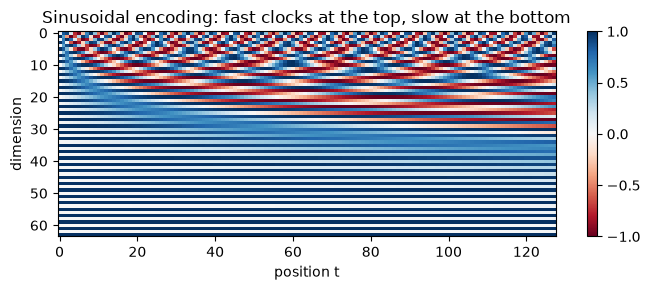

In [3]:
# 🧪 [Added]
def sinusoidal(T, d, base=10000.0):
    pos = torch.arange(T)[:, None].float()
    theta = base ** (-torch.arange(0, d, 2).float() / d)
    pe = torch.zeros(T, d)
    pe[:, 0::2] = torch.sin(pos * theta)
    pe[:, 1::2] = torch.cos(pos * theta)
    return pe

plt.figure(figsize=(7, 3))
plt.imshow(sinusoidal(128, 64).T, aspect="auto", cmap="RdBu"); plt.colorbar()
plt.xlabel("position t"); plt.ylabel("dimension"); plt.title("Sinusoidal encoding: fast clocks at the top, slow at the bottom")
plt.tight_layout(); plt.show()

Absolute encodings are **added once** at the input. The relative offset between two tokens is then only implicitly available inside attention. RoPE makes it explicit.

## 3. Rotary position embeddings (RoPE)

📗 *[GPT→Llama 2] text, code and figure; 🧪 [Added] math*

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/04-positional_encoding_rope/img/gpt2-to-llama2-llama3.webp?raw=true" width="700px">

*Figure: GPT-2 vs Llama 2 vs Llama 3 — note the learned positional embedding in GPT-2 replaced by RoPE inside attention. Source: Raschka, LLMs-from-scratch, GPT-to-Llama bonus (original image `bonus/gpt-to-llama/gpt2-to-llama2-llama3.webp`).*

- Unlike traditional absolute positional embeddings, Llama uses rotary position embeddings (RoPE), which capture both absolute and relative positional information simultaneously ([RoFormer, 2021](https://arxiv.org/abs/2104.09864)).
- RoPE can be implemented in two equivalent ways: the *split-halves* version and the *interleaved even/odd* version; they are mathematically the same as long as dimensions are paired consistently and the same cos/sin ordering is used.
- The code below uses the *split-halves* approach, like Hugging Face transformers; the original RoPE paper and Meta's official Llama 2 repository use the *interleaved* version.

🧪 **The math.** Split a head vector into pairs; pair $i$ at position $m$ is rotated by angle $m\theta_i$ with $\theta_i=b^{-2i/d_h}$:

$$
\begin{pmatrix} x'_{a} \\ x'_{b}\end{pmatrix}
=\begin{pmatrix}\cos m\theta_i & -\sin m\theta_i\\ \sin m\theta_i & \cos m\theta_i\end{pmatrix}
\begin{pmatrix} x_{a} \\ x_{b}\end{pmatrix}.
$$

Rotations compose, $R_m^\top R_n = R_{n-m}$, so $\langle R_m q, R_n k\rangle = q^\top R_{n-m}k$ depends only on the **relative offset** $n-m$. Absolute rotations in, relative attention out.

In [4]:
# Source: Raschka, LLMs-from-scratch, converting-gpt-to-llama2.ipynb (Apache-2.0)
def precompute_rope_params(head_dim, theta_base=10_000, context_length=4096):
    assert head_dim % 2 == 0, "Embedding dimension must be even"

    # Compute the inverse frequencies
    inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2)[: (head_dim // 2)].float() / head_dim))

    # Generate position indices
    positions = torch.arange(context_length)

    # Compute the angles
    angles = positions.unsqueeze(1) * inv_freq.unsqueeze(0)  # Shape: (context_length, head_dim // 2)

    # Expand angles to match the head_dim
    angles = torch.cat([angles, angles], dim=1)  # Shape: (context_length, head_dim)

    # Precompute sine and cosine
    cos = torch.cos(angles)
    sin = torch.sin(angles)

    return cos, sin

def compute_rope(x, cos, sin):
    # x: (batch_size, num_heads, seq_len, head_dim)
    batch_size, num_heads, seq_len, head_dim = x.shape
    assert head_dim % 2 == 0, "Head dimension must be even"

    # Split x into first half and second half
    x1 = x[..., : head_dim // 2]  # First half
    x2 = x[..., head_dim // 2 :]  # Second half

    # Adjust sin and cos shapes
    cos = cos[:seq_len, :].unsqueeze(0).unsqueeze(0)  # Shape: (1, 1, seq_len, head_dim)
    sin = sin[:seq_len, :].unsqueeze(0).unsqueeze(0)

    # Apply the rotary transformation
    rotated = torch.cat((-x2, x1), dim=-1)
    x_rotated = (x * cos) + (rotated * sin)

    return x_rotated.to(dtype=x.dtype)

Applying RoPE to example `q` and `k` tensors (shapes are unchanged):

In [5]:
# Source: Raschka, LLMs-from-scratch, converting-gpt-to-llama2.ipynb (Apache-2.0)
# Settings
batch_size = 2
context_len = 5
num_heads = 4
head_dim = 16

# Instantiate RoPE parameters
cos, sin = precompute_rope_params(head_dim=head_dim, context_length=context_len)

# Dummy query and key tensors
torch.manual_seed(123)
queries = torch.randn(batch_size, num_heads, context_len, head_dim)
keys = torch.randn(batch_size, num_heads, context_len, head_dim)

# Apply rotary position embeddings
queries_rot = compute_rope(queries, cos, sin)
keys_rot = compute_rope(keys, cos, sin)

print(queries_rot.shape, keys_rot.shape)

torch.Size([2, 4, 5, 16]) torch.Size([2, 4, 5, 16])


**Where RoPE goes.** GPT applies positional embeddings to the *inputs*, whereas Llama applies rotations to the query and key vectors *inside* the self-attention mechanism (the `# NEW` parts below). The precomputed `cos`/`sin` tables are registered as buffers.

```
x ─► W_Q ─► q ─► RoPE(q, pos) ─┐
                               ├─► softmax(q·kᵀ/√d_h + mask) ─► · v
x ─► W_K ─► k ─► RoPE(k, pos) ─┘                                 ▲
x ─► W_V ─► v ───────────────────────────────────────────────────┘   (V is NOT rotated)
```

In [6]:
# Source: Raschka, LLMs-from-scratch, converting-gpt-to-llama2.ipynb (Apache-2.0)
#####################################
# Chapter 3
#####################################
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, num_heads, dtype=None):  # ,dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by n_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads  # Reduce the projection dim to match desired output dim

        ################################### NEW ###################################
        # Set bias=False and dtype=dtype for all linear layers below
        ###########################################################################
        self.W_query = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.W_key = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.W_value = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.out_proj = nn.Linear(d_out, d_out, bias=False, dtype=dtype)  # Linear layer to combine head outputs
        # self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

        ################################### NEW ###################################
        cos, sin = precompute_rope_params(head_dim=self.head_dim, context_length=context_length)
        self.register_buffer("cos", cos)
        self.register_buffer("sin", sin)
        ###########################################################################


    def forward(self, x):

        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        ################################### NEW ###################################
        keys = compute_rope(keys, self.cos, self.sin)
        queries = compute_rope(queries, self.cos, self.sin)
        ###########################################################################

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        # attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.reshape(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)  # optional projection

        return context_vec

mha = MultiHeadAttention(d_in=128, d_out=128, context_length=4096, num_heads=4)
print(mha(torch.randn(1, 100, 128)).shape)

torch.Size([1, 100, 128])


## 4. Testing the key properties

🧪 *[Added], using Raschka's `precompute_rope_params` / `compute_rope`*

In [7]:
# 🧪 [Added]
head_dim = 16
cos, sin = precompute_rope_params(head_dim=head_dim, context_length=1024)
q, k = torch.randn(head_dim), torch.randn(head_dim)

def rotate_at(v, pos):
    """Rotate a single head vector as if it sat at position `pos`."""
    x = v.view(1, 1, 1, -1)
    return compute_rope(x, cos[pos:pos + 1], sin[pos:pos + 1]).view(-1)

def score(m, n):
    return (rotate_at(q, m) @ rotate_at(k, n)).item()

# (1) relative: shifting both positions by the same amount leaves the score unchanged
for m, n in [(0, 3), (10, 13), (500, 503)]:
    print(f"score(m={m:3d}, n={n:3d}) = {score(m, n):+.5f}")
assert abs(score(0, 3) - score(500, 503)) < 1e-4
print("depends only on n - m ✓")

# (2) rotations preserve length; (3) position 0 is the identity
x = torch.randn(1, 1, 6, head_dim)
xr = compute_rope(x, cos, sin)
assert torch.allclose(xr.norm(dim=-1), x.norm(dim=-1), atol=1e-5)
assert torch.allclose(xr[..., 0, :], x[..., 0, :])
print("norms preserved ✓   position 0 unrotated ✓")

score(m=  0, n=  3) = +0.34186
score(m= 10, n= 13) = +0.34186
score(m=500, n=503) = +0.34186
depends only on n - m ✓
norms preserved ✓   position 0 unrotated ✓


🧪 **The two layouts.** The interleaved version (paper, Meta's reference code) pairs $(x_0,x_1),(x_2,x_3),\dots$; the split-halves version pairs $(x_i, x_{i+d/2})$. They agree up to a fixed permutation of the dimensions — but **a checkpoint only works with the layout it was trained with**, so weight converters permute the rows of $W_Q, W_K$ (a classic bug when skipped).

In [8]:
# 🧪 [Added]
def rope_interleaved(x, positions, base=10_000):
    theta = base ** (-torch.arange(0, x.shape[-1], 2).float() / x.shape[-1])
    angles = positions[:, None].float() * theta
    xc = torch.view_as_complex(x.float().reshape(*x.shape[:-1], -1, 2).contiguous())
    return torch.view_as_real(xc * torch.polar(torch.ones_like(angles), angles)).flatten(-2)

x = torch.randn(1, 1, 6, head_dim)
perm = torch.cat([torch.arange(0, head_dim, 2), torch.arange(1, head_dim, 2)])
a = rope_interleaved(x, torch.arange(6))[..., perm]
b = compute_rope(x[..., perm], cos, sin)
assert torch.allclose(a, b, atol=1e-5)
print("interleaved == split-halves up to a dimension permutation ✓")

interleaved == split-halves up to a dimension permutation ✓


## 5. RoPE in practice

### With a KV cache

🧪 *[Added]*

Cache **already-rotated** keys. When decoding token number $t$, rotate its query and key with the **absolute** position $t$, not 0. Forgetting this offset is a common bug: everything runs, but quality silently drops.

In [9]:
# 🧪 [Added]
def attend_rope(Q, K, V, q_pos, k_pos):
    qr = compute_rope(Q[None, None], cos[q_pos], sin[q_pos])[0, 0]
    kr = compute_rope(K[None, None], cos[k_pos], sin[k_pos])[0, 0]
    s = qr @ kr.T / math.sqrt(Q.shape[-1])
    s = s.masked_fill(k_pos[None, :] > q_pos[:, None], float("-inf"))
    return F.softmax(s, -1) @ V

T = 10
Q, K, V = (torch.randn(T, head_dim) for _ in range(3))
full = attend_rope(Q, K, V, torch.arange(T), torch.arange(T))
last_correct = attend_rope(Q[-1:], K, V, torch.tensor([T - 1]), torch.arange(T))
last_bug = attend_rope(Q[-1:], K, V, torch.tensor([0]), torch.arange(T))
print("correct offset matches full pass:", torch.allclose(full[-1:], last_correct, atol=1e-6))
print("offset bug matches full pass:   ", torch.allclose(full[-1:], last_bug, atol=1e-6))

correct offset matches full pass: True
offset bug matches full pass:    False


### Long-range decay

🧪 *[Added]*

The attention a query can give a key tends to shrink with distance (Su et al. show a decaying upper bound): fast-rotating pairs average out over long distances, and only slow pairs keep agreeing. Nearby tokens matter more by default, but the model can still learn to look far.

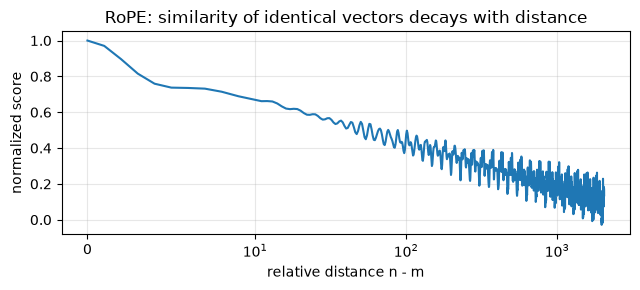

In [10]:
# 🧪 [Added]
theta = 1.0 / (10_000 ** (torch.arange(0, 128, 2).float() / 128))
dist = torch.arange(0, 2048)
s = (2 * torch.cos(dist[:, None] * theta[None, :])).sum(-1)   # q = k = all-ones
plt.figure(figsize=(6.5, 3))
plt.plot(dist, s / s[0]); plt.xscale("symlog", linthresh=10)
plt.xlabel("relative distance n - m"); plt.ylabel("normalized score")
plt.title("RoPE: similarity of identical vectors decays with distance")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Llama 3: a larger base, and frequency scaling for long context

📗 *[Llama 2→3] text and code; 🧪 [Added] wavelength check*

- Llama 3 supports up to 8,192 tokens, twice Llama 2's 4,096.
- The base of RoPE's $\theta$ increased from 10,000 (Llama 2) to 500,000 (Llama 3):

$$\Theta = \left\{\theta_i = \text{base}^{\frac{-2(i-1)}{d}}, i \in \left[1, 2, ..., d/2\right]\right\}$$

- Increasing the base makes the frequencies decay faster across the dimensions: higher-dimensional components get smaller rotation angles than before, which better supports longer contexts.

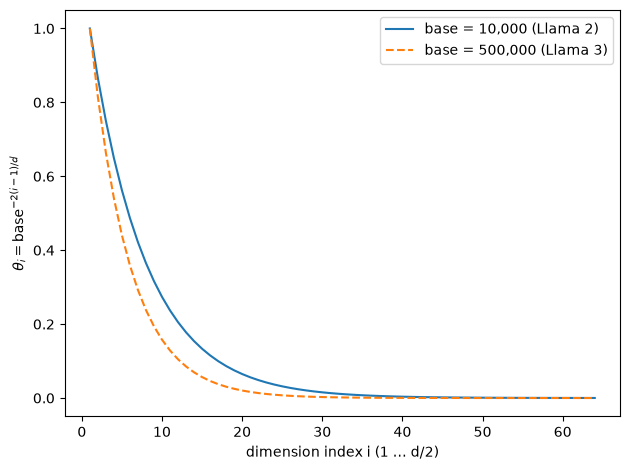

In [11]:
# Source: Raschka, LLMs-from-scratch, converting-llama2-to-llama3.ipynb (Apache-2.0)
import matplotlib.pyplot as plt
import torch

d = 128
i = torch.arange(1, d // 2 + 1)

base_llama2 = 10_000
base_llama3 = 500_000

theta_llama2 = base_llama2 ** (-2 * (i - 1) / d)
theta_llama3 = base_llama3 ** (-2 * (i - 1) / d)

plt.plot(i, theta_llama2, label="base = 10,000 (Llama 2)")
plt.plot(i, theta_llama3, label="base = 500,000 (Llama 3)", ls="--")
plt.xlabel("dimension index i (1 … d/2)")
plt.ylabel(r"$\theta_i = \mathrm{base}^{-2(i-1)/d}$")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# 🧪 [Added] the slowest pair's wavelength ≈ the longest distance the encoding can tell apart
for base in (10_000, 500_000):
    th = 1.0 / (base ** (torch.arange(0, 128, 2).float() / 128))
    print(f"base {base:>7,}: fastest wavelength {2 * math.pi / th[0]:6.1f} tokens, slowest {2 * math.pi / th[-1]:>12,.0f} tokens")

base  10,000: fastest wavelength    6.3 tokens, slowest       54,410 tokens
base 500,000: fastest wavelength    6.3 tokens, slowest    2,559,196 tokens


📗 Llama 3.1 extends the context to 128k tokens with a **frequency adjustment** (`freq_config`): low-frequency components (long wavelengths) are divided by a factor, high-frequency ones are kept, and medium ones are smoothly interpolated. Raschka's Llama 3 version of `precompute_rope_params`:

In [13]:
# Source: Raschka, LLMs-from-scratch, converting-llama2-to-llama3.ipynb (Apache-2.0)
import torch

def precompute_rope_params(head_dim, theta_base=10_000, context_length=4096, freq_config=None):
    assert head_dim % 2 == 0, "Embedding dimension must be even"

    # Compute the inverse frequencies
    inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2)[: (head_dim // 2)].float() / head_dim))

    ################################ NEW ###############################################
    # Frequency adjustments
    if freq_config is not None:
        low_freq_wavelen = freq_config["original_context_length"] / freq_config["low_freq_factor"]
        high_freq_wavelen = freq_config["original_context_length"] / freq_config["high_freq_factor"]

        wavelen = 2 * torch.pi / inv_freq

        inv_freq_llama = torch.where(
            wavelen > low_freq_wavelen, inv_freq / freq_config["factor"], inv_freq
        )

        smooth_factor = (freq_config["original_context_length"] / wavelen - freq_config["low_freq_factor"]) / (
            freq_config["high_freq_factor"] - freq_config["low_freq_factor"]
        )

        smoothed_inv_freq = (
            (1 - smooth_factor) * (inv_freq / freq_config["factor"]) + smooth_factor * inv_freq
        )

        is_medium_freq = (wavelen <= low_freq_wavelen) & (wavelen >= high_freq_wavelen)
        inv_freq_llama = torch.where(is_medium_freq, smoothed_inv_freq, inv_freq_llama)
        inv_freq = inv_freq_llama
    ####################################################################################


    # Generate position indices
    positions = torch.arange(context_length)

    # Compute the angles
    angles = positions.unsqueeze(1) * inv_freq.unsqueeze(0)  # Shape: (context_length, head_dim // 2)

    # Expand angles to match the head_dim
    angles = torch.cat([angles, angles], dim=1)  # Shape: (context_length, head_dim)

    # Precompute sine and cosine
    cos = torch.cos(angles)
    sin = torch.sin(angles)

    return cos, sin

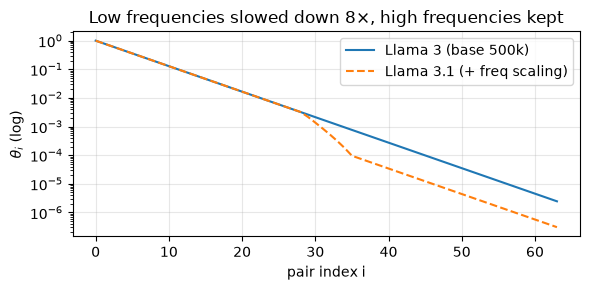

In [14]:
# 🧪 [Added] compare Llama 3 vs Llama 3.1 rotation frequencies (config values from Raschka's LLAMA31_CONFIG_8B)
llama31_freq = {"factor": 8.0, "low_freq_factor": 1.0, "high_freq_factor": 4.0, "original_context_length": 8192}
cos3, sin3 = precompute_rope_params(128, theta_base=500_000, context_length=2)
cos31, sin31 = precompute_rope_params(128, theta_base=500_000, context_length=2, freq_config=llama31_freq)
inv3 = torch.atan2(sin3[1, :64], cos3[1, :64])      # angle at position 1 = θ_i (atan2 stays precise for tiny angles)
inv31 = torch.atan2(sin31[1, :64], cos31[1, :64])
plt.figure(figsize=(6, 3))
plt.semilogy(inv3, label="Llama 3 (base 500k)"); plt.semilogy(inv31, "--", label="Llama 3.1 (+ freq scaling)")
plt.xlabel("pair index i"); plt.ylabel(r"$\theta_i$ (log)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Low frequencies slowed down 8×, high frequencies kept"); plt.tight_layout(); plt.show()

🧪 Other context-extension methods follow the same idea — *position interpolation* (squeeze new positions into the trained range), *NTK-aware scaling* (enlarge the base) and *YaRN* (frequency-dependent scaling plus an attention temperature) — each followed by a short fine-tune on long documents.

## 6. Check yourself (interview-style)

🧪 *[Added]*

<details><summary><b>Q1. Why do Transformers need positional information at all?</b></summary>

Self-attention is permutation-equivariant: it treats the input as a set. Without positions, "dog bites man" and "man bites dog" produce the same multiset of representations. Position information is added to the input (learned/sinusoidal), injected into Q and K (RoPE), or added as a bias on scores (ALiBi, T5 relative bias).
</details>

<details><summary><b>Q2. Explain RoPE and why it encodes relative position.</b></summary>

Split each Q/K head vector into 2-D pairs and rotate pair $i$ by $m\theta_i$, with $m$ the token position and $\theta_i=b^{-2i/d}$. Because $R_m^\top R_n=R_{n-m}$, $\langle R_mq,R_nk\rangle=q^\top R_{n-m}k$ depends only on $n-m$. Applied to Q and K (not V) in every layer, no parameters, norm-preserving, works naturally with a KV cache.
</details>

<details><summary><b>Q3. Why is RoPE generally preferred over learned absolute or sinusoidal embeddings?</b></summary>

Relative position falls out of the score directly, which generalizes better; there is no $T_{\max}$-sized table; it has a mild long-range decay bias; and its frequency structure enables context extension (larger base, Llama 3.1-style frequency scaling, interpolation, NTK, YaRN) with modest fine-tuning. Learned absolute embeddings cannot go past their trained length at all.
</details>

<details><summary><b>Q4. Why rotate Q and K but not V?</b></summary>

Position should affect *which* tokens attend to which (the scores), and only Q and K enter the scores. Rotating V would mix position into the aggregated content without giving the relative-position property.
</details>

<details><summary><b>Q5. A converted checkpoint generates garbage, but shapes are fine. One RoPE-related suspect?</b></summary>

The pairing layout: interleaved (Meta reference) vs split-halves (Hugging Face). Converters permute the $W_Q/W_K$ rows to match; skipping that silently breaks attention. Other suspects: wrong base (10k vs 500k), missing frequency scaling, or the absolute-position offset during cached decoding.
</details>

## References

- Raschka, LLMs-from-scratch: [GPT → Llama 2](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch05/07_gpt_to_llama/converting-gpt-to-llama2.ipynb) and [Llama 2 → Llama 3](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch05/07_gpt_to_llama/converting-llama2-to-llama3.ipynb) (Apache-2.0).
- Su et al. (2021), *RoFormer*, [arXiv:2104.09864](https://arxiv.org/abs/2104.09864); Vaswani et al. (2017), [arXiv:1706.03762](https://arxiv.org/abs/1706.03762).
- Chen et al. (2023), *Position Interpolation*, [arXiv:2306.15595](https://arxiv.org/abs/2306.15595); Peng et al. (2023), *YaRN*, [arXiv:2309.00071](https://arxiv.org/abs/2309.00071).